# Experiment evaluation – Vanguard A/B test
**Team:** Juliana · Raquel · Lervin

This notebook brings together the three KPI analyses and evaluates the **experiment itself**:

| Section | Question |
|---|---|
| 0 | Setup and the three KPI results in one table |
| 1 | **Design effectiveness:** was the experiment well structured? Were clients split randomly and equally? Any bias? |
| 2 | **Duration:** was 15 Mar – 20 Jun 2017 long enough? How do the KPIs change over the months? |
| 3 | **Additional data needs:** what other data would improve the analysis? |
| 4 | **Final verdict and recommendation** for Vanguard |

**Data:** merged file `vanguard_master_merged` (web data + experiment roster + client profiles), in `data/clean/`.

**Source notebooks:**
- `KPI - Completion Rate.ipynb` (Lervin)
- `KPI - Time spent on each step.ipynb` (Juliana)
- `error_rate_analysis_final.ipynb` (Raquel)

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

STEP_ORDER = {"start": 0, "step_1": 1, "step_2": 2, "step_3": 3, "confirm": 4}
STEPS = list(STEP_ORDER)
GROUPS = ["Control", "Test"]
MAX_SECONDS = 30 * 60
alpha = 0.05

# same colours as the KPI notebooks
COLORS = {"Control": "#eb6834", "Test": "#2a78d6"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.max_columns", None)

In [2]:
csv_path = CLEAN_DIR / "vanguard_master_merged.csv"
DATA_FILE = csv_path if csv_path.exists() else CLEAN_DIR / "vanguard_master_merged.zip"
df_all = pd.read_csv(DATA_FILE, parse_dates=["date_time"], low_memory=False)
print(f"{DATA_FILE.name}: {df_all.shape[0]:,} rows x {df_all.shape[1]} columns")

vanguard_master_merged.csv: 744,641 rows x 14 columns


### Prepare the data (same rules as the three KPI notebooks)
1. Keep only **Test and Control** clients
2. A visit = **`client_id` + `visit_id`** (the same `visit_id` is used by different clients)
3. Sort each visit by time (same second → earlier step first)
4. **Error** = moving to an earlier step · **Time on step** = seconds until the next action (pauses > 30 min excluded)

In [3]:
df = df_all[df_all["variation"].isin(GROUPS)].copy()
df["visit_key"] = df["client_id"].astype(str) + "_" + df["visit_id"].astype(str)
df["step_num"] = df["process_step"].map(STEP_ORDER)
df = df.sort_values(["visit_key", "date_time", "step_num"]).reset_index(drop=True)

g = df.groupby("visit_key", sort=False)
df["backward"] = df["step_num"] < g["step_num"].shift()
df["step_seconds"] = (g["date_time"].shift(-1) - df["date_time"]).dt.total_seconds()
df["valid_time"] = df["step_seconds"].between(0, MAX_SECONDS) & (df["process_step"] != "confirm")
df["month"] = df["date_time"].dt.to_period("M")

# one row per client: group, profile, first visit, completed?
clients = (df.groupby("client_id")
             .agg(variation=("variation", "first"), first_visit=("date_time", "min"),
                  completed=("process_step", lambda s: (s == "confirm").any()),
                  clnt_age=("clnt_age", "first"), clnt_tenure_yr=("clnt_tenure_yr", "first"),
                  bal=("bal", "first"), num_accts=("num_accts", "first"),
                  logons_6_mnth=("logons_6_mnth", "first"), calls_6_mnth=("calls_6_mnth", "first"),
                  gendr=("gendr", "first")))
clients["start_month"] = clients["first_visit"].dt.to_period("M")

print(f"Actions: {len(df):,} | Visits: {df['visit_key'].nunique():,} | Clients: {len(clients):,}")

Actions: 317,235 | Visits: 69,447 | Clients: 50,500


### The three KPIs in one table
Recalculated here with the same rules, so they match the KPI notebooks.

In [4]:
comp = clients.groupby("variation")["completed"].mean()
err = df.groupby("variation")["backward"].mean()
tim = df[df["valid_time"]].groupby("variation")["step_seconds"].mean()
step1 = df[df["valid_time"] & (df["process_step"] == "step_1")].groupby("variation")["step_seconds"].mean()

kpis = pd.DataFrame({
    "KPI": ["Completion rate (clients)", "Error rate (backward steps ÷ steps)",
            "Avg time per step (s)", "Avg time on step_1 (s)"],
    "Control": [comp["Control"], err["Control"], tim["Control"], step1["Control"]],
    "Test": [comp["Test"], err["Test"], tim["Test"], step1["Test"]],
    "Better if": ["higher", "lower", "lower", "lower"],
})
kpis["Test − Control"] = kpis["Test"] - kpis["Control"]
kpis["Winner"] = np.where((kpis["Test − Control"] > 0) == (kpis["Better if"] == "higher"), "Test", "Control")
fmt = lambda r: (f"{r:.1%}" if abs(r) < 1 else f"{r:.1f}")
kpis.assign(**{c: kpis[c].map(fmt) for c in ["Control", "Test"]},
            **{"Test − Control": kpis["Test − Control"].map(lambda v: f"{v*100:+.1f} pp" if abs(v) < 1 else f"{v:+.1f} s")})

,KPI,Control,Test,Better if,Test − Control,Winner
0,Completion rate (clients),65.6%,69.3%,higher,+3.7 pp,Test
1,Error rate (backward steps ÷ steps),6.7%,9.2%,lower,+2.4 pp,Control
2,Avg time per step (s),78.0,75.9,lower,-2.1 s,Test
3,Avg time on step_1 (s),47.5,58.4,lower,+11.0 s,Control


## 1. Design effectiveness

**Was the experiment well structured?** A good A/B test needs:
1. Each client sees **only one** design, and both designs run **at the same time**
2. A **similar number** of clients in each group (ideally 50/50)
3. **Similar clients** in both groups, so differences come from the **design** and not from different people

### 1.1 Each client in one group, both groups at the same time

In [5]:
groups_per_client = df.groupby("client_id")["variation"].nunique()
print("Clients in more than one group:", (groups_per_client > 1).sum())
print()
print("Activity period by group:")
df.groupby("variation")["date_time"].agg(first="min", last="max")

Clients in more than one group: 0

Activity period by group:


,first,last
variation,,
Control,2017-03-15 00:19:28,2017-06-20 23:57:06
Test,2017-03-15 00:43:23,2017-06-20 23:21:23


### 1.2 Group split: is it 50/50?
**Chi-square goodness-of-fit test** · H0: clients were split 50/50 · H1: the split is not 50/50 · α = 0.05

In [6]:
split = clients["variation"].value_counts().reindex(GROUPS).to_frame("clients")
split["share"] = split["clients"] / split["clients"].sum()
chi2, p_split = stats.chisquare(split["clients"])
print(f"Chi-square = {chi2:.1f}, p-value = {p_split:.2e} → "
      + ("reject H0: the split is NOT 50/50" if p_split < alpha else "fail to reject H0: split is 50/50"))
split.style.format({"clients": "{:,}", "share": "{:.1%}"})

Chi-square = 233.8, p-value = 8.92e-53 → reject H0: the split is NOT 50/50


,clients,share
variation,,
Control,"23,532",46.6%
Test,"26,968",53.4%


### 1.3 Client profile balance: are the groups similar?
For each characteristic: **two-sample t-test** (H0: same average in Test and Control). For gender: **chi-square test** (H0: same gender mix).

In [7]:
rows = []
for col, label in [("clnt_age", "Age (years)"), ("clnt_tenure_yr", "Tenure (years)"), ("bal", "Balance ($)"),
                   ("num_accts", "Number of accounts"), ("logons_6_mnth", "Logons last 6 months"),
                   ("calls_6_mnth", "Calls last 6 months")]:
    c = clients.loc[clients["variation"] == "Control", col].dropna()
    t = clients.loc[clients["variation"] == "Test", col].dropna()
    p = stats.ttest_ind(t, c, equal_var=False).pvalue
    rows.append({"Characteristic": label, "Control avg": c.mean(), "Test avg": t.mean(),
                 "Difference (%)": t.mean() / c.mean() - 1, "p-value": p})
balance = pd.DataFrame(rows).set_index("Characteristic")

gender = pd.crosstab(clients["variation"], clients["gendr"])
p_gender = stats.chi2_contingency(gender)[1]
print(f"Gender mix: chi-square p-value = {p_gender:.2f} → "
      + ("different" if p_gender < alpha else "no significant difference"))

balance.style.format({"Control avg": "{:,.2f}", "Test avg": "{:,.2f}", "Difference (%)": "{:+.1%}", "p-value": "{:.3f}"})

Gender mix: chi-square p-value = 0.31 → no significant difference


,Control avg,Test avg,Difference (%),p-value
Characteristic,,,,
Age (years),47.50,47.16,-0.7%,0.016
Tenure (years),12.09,11.98,-0.9%,0.087
Balance ($),"150,147.33","148,962.61",-0.8%,0.659
Number of accounts,2.26,2.25,-0.4%,0.036
Logons last 6 months,6.17,6.10,-1.0%,0.001
Calls last 6 months,3.13,3.06,-2.1%,0.001


In [8]:
pd.crosstab(clients["variation"], clients["gendr"], normalize="index").style.format("{:.1%}")

gendr,F,M,U,X
variation,,,,
Control,32.1%,33.9%,34.1%,0.0%
Test,32.3%,33.3%,34.4%,0.0%


### Design effectiveness – answer

| Check | Result | OK? |
|---|---|---|
| Each client saw only one design | 0 clients in both groups | ✅ |
| Both designs ran at the same time | Both groups active 15 Mar – 20 Jun 2017 | ✅ |
| 50/50 split | **53.4% Test / 46.6% Control** (26,968 vs 23,532); chi-square p < 0.001 → not exactly equal | ⚠️ |
| Similar clients | Age, tenure, balance, accounts and gender mix differ by **≤ 1–2%**; some p-values < 0.05 only because the samples are huge (e.g. age 47.2 vs 47.5 years) | ✅ |

**Conclusion:** the experiment is **well structured**. Clients appear to be **randomly assigned**: the two groups have practically the same profile. The split is **not exactly 50/50**, but both groups are very large (>23,000 clients), so the comparison is reliable as long as we compare **rates and averages**, never totals.

**Possible biases**
- **Unequal split (53/47):** small and not harmful with these sample sizes, but it should be explained (it may come from how clients were sampled).
- **Novelty / learning effect:** the new design is unfamiliar at first. Its results change over the months (see section 2).
- **Repeated visits:** one client can have several visits, so visits and steps are not fully independent. That's why completion is measured per **client**, and the error rate was also checked at visit and client level.
- **Unknown context:** no device, browser or reason for the visit. If, for example, more Test clients used mobile, that could affect time and errors.
- **Selection:** only clients who **started** the online process are in the data. We can't see clients who never tried.

## 2. Duration: was 15 Mar – 20 Jun 2017 long enough?
We check **when clients entered** the experiment and whether each KPI is **stable over the months**.

### 2.1 Clients per month (month of their first visit)

In [9]:
per_month = clients.pivot_table(index="start_month", columns="variation", values="completed", aggfunc="size")[GROUPS]
per_month["Total"] = per_month.sum(axis=1)
per_month["Share of clients"] = per_month["Total"] / per_month["Total"].sum()
per_month.style.format({"Control": "{:,}", "Test": "{:,}", "Total": "{:,}", "Share of clients": "{:.0%}"})

variation,Control,Test,Total,Share of clients
start_month,,,,
2017-03,"4,744","5,837","10,581",21%
2017-04,"13,271","16,176","29,447",58%
2017-05,"3,494","3,269","6,763",13%
2017-06,"2,023","1,686","3,709",7%


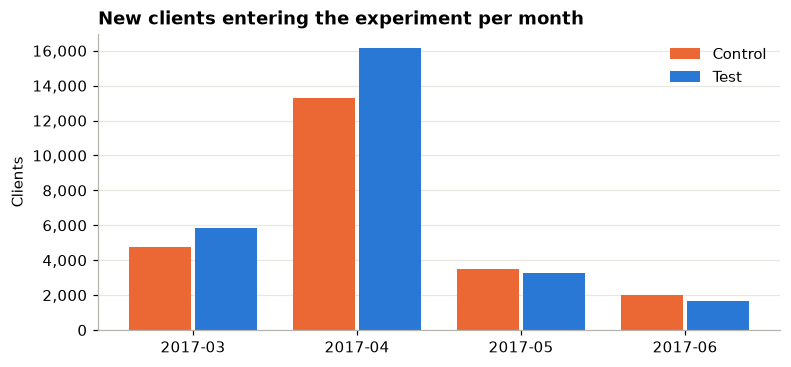

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(per_month)); w = 0.38
for i, gname in enumerate(GROUPS):
    ax.bar(x + (i - 0.5) * (w + 0.02), per_month[gname], width=w, color=COLORS[gname], label=gname)
ax.set_xticks(x); ax.set_xticklabels(per_month.index.astype(str))
ax.set_title("New clients entering the experiment per month", loc="left"); ax.set_ylabel("Clients")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}")); ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.savefig(FIG_DIR / "eval_clients_per_month.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.2 Each KPI over the months
- **Completion rate:** clients grouped by the month of their **first** visit
- **Error rate** and **time per step:** actions grouped by the month they happened

In [11]:
comp_m = clients.pivot_table(index="start_month", columns="variation", values="completed", aggfunc="mean")[GROUPS]
err_m = df.pivot_table(index="month", columns="variation", values="backward", aggfunc="mean")[GROUPS]
time_m = df[df["valid_time"]].pivot_table(index="month", columns="variation", values="step_seconds", aggfunc="mean")[GROUPS]
step1_m = (df[df["valid_time"] & (df["process_step"] == "step_1")]
             .pivot_table(index="month", columns="variation", values="step_seconds", aggfunc="mean")[GROUPS])

trend = pd.DataFrame({
    "Completion – Test−Control (pp)": (comp_m["Test"] - comp_m["Control"]) * 100,
    "Error rate – Test−Control (pp)": (err_m["Test"] - err_m["Control"]) * 100,
    "Avg time/step – Test−Control (s)": time_m["Test"] - time_m["Control"],
    "Time on step_1 – Test−Control (s)": step1_m["Test"] - step1_m["Control"],
})
trend.index = trend.index.astype(str)
print("Difference Test − Control per month (completion: + is good; errors and time: − is good)")
trend.round(1)

Difference Test − Control per month (completion: + is good; errors and time: − is good)


,Completion – Test−Control (pp),Error rate – Test−Control (pp),Avg time/step – Test−Control (s),Time on step_1 – Test−Control (s)
2017-03,5.2,3.1,-9.1,17.0
2017-04,2.7,3.0,-2.7,14.2
2017-05,2.8,1.9,2.3,2.8
2017-06,0.5,-0.3,2.6,-7.3


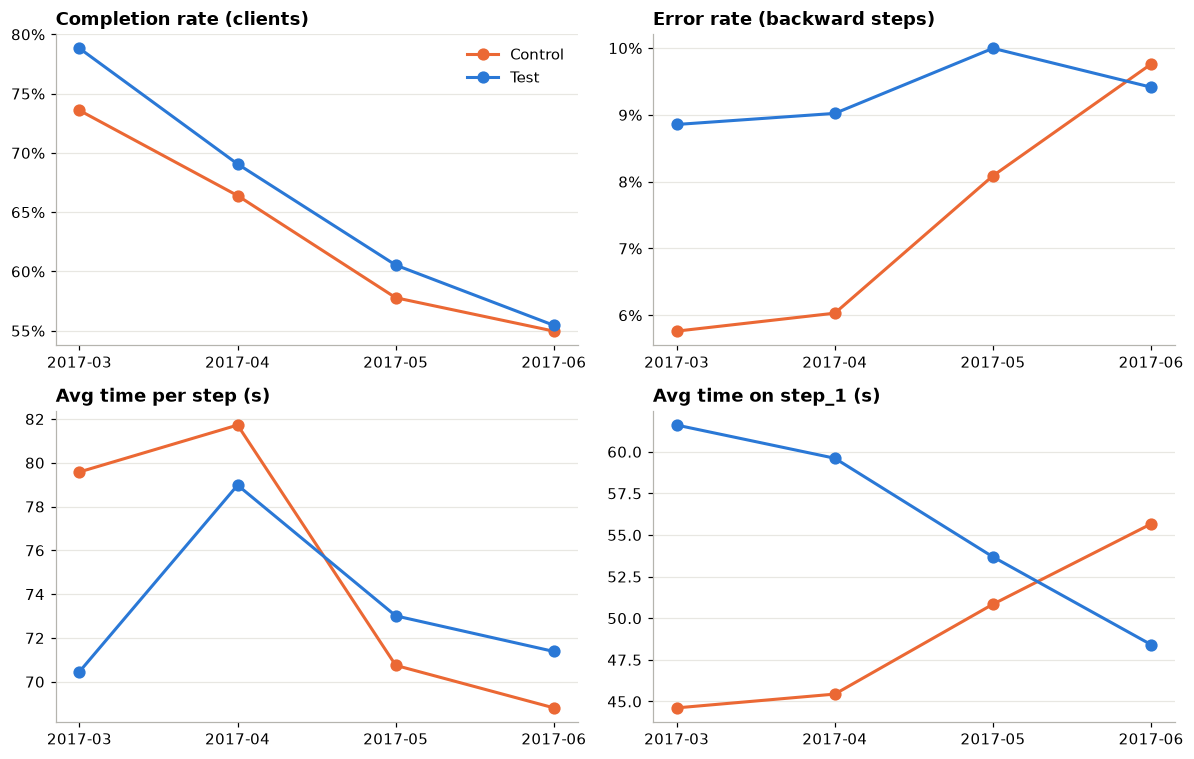

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [(comp_m, "Completion rate (clients)", True), (err_m, "Error rate (backward steps)", True),
          (time_m, "Avg time per step (s)", False), (step1_m, "Avg time on step_1 (s)", False)]
for ax, (table, title, pct) in zip(axes.flat, panels):
    xs = table.index.astype(str)
    for gname in GROUPS:
        ax.plot(xs, table[gname], marker="o", markersize=7, linewidth=2, color=COLORS[gname], label=gname)
    ax.set_title(title, loc="left"); ax.grid(axis="x", visible=False)
    if pct: ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "eval_kpis_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

### Duration – answer

**Enough data?** Yes. About 3 months gave **50,500 clients**, more than enough to detect differences of a few percentage points or a few seconds with confidence.

**But the data is not spread evenly over time:**
- **~80% of clients entered in March–April**, and only ~20% in May–June. The last weeks add little data.
- March–April is the **US tax-filing season** (deadline mid-April). Clients may behave differently from the rest of the year.

**The advantage of the new design changes over the months:**

| KPI | March | June | Trend |
|---|---|---|---|
| Completion (Test − Control) | **+5.2 pp** | +0.5 pp | Advantage **shrinks** |
| Error rate (Test − Control) | **+3.1 pp** | −0.3 pp | Gap closes (Control gets worse) |
| Avg time per step (Test − Control) | **−9 s** | +3 s | Speed advantage **disappears** |
| Time on step_1 (Test − Control) | **+17 s** | −7 s | Extra time **disappears** |

- **Time on step_1:** Test clients get clearly faster (≈ 62 s → 48 s). They seem to **learn** the new design, so its weak point becomes less of a problem with time.
- **Error rate:** the gap closes mainly because **Control errors rise** (≈ 6% → 10%), while Test stays around 9–10%. So this is **not** a sign that the new design improved; the late-month clients behave differently in both groups.
- **Average time per step:** Test was faster at the start, but by May–June both groups take about the same time, and Test is even slightly slower.
- **Completion shrinks:** part of the early gain may be a **novelty effect**. The new design looked attractive at first.
- **Clients who entered late** (May–June) had **less time left** to come back and finish before the test ended. That alone lowers their completion rate in both groups.

**Conclusion:** the duration was **enough for the sample size**, but **not enough to know the long-term effect**. The KPIs were still moving at the end of the test, and May–June have little data. A **longer test** (or one with more traffic after the tax season) would show where the results settle.

## 3. Additional data needs
Combined list from the three KPI analyses:

| Data | Why it would help | KPI it helps |
|---|---|---|
| **Device / browser / app vs web** | Mobile users may struggle more with the new `step_1`. Explains time and errors | Time, errors |
| **Events inside each page** (clicks, form fields, validation errors, help clicks) | Explains **why** clients go back from `step_1` to `start` and spend longer there | Errors, time |
| **Exit page / abandonment reason** | Shows **where** and **why** clients leave without confirming | Completion |
| **Page load time** | Separates "slow page" from "client thinking" | Time |
| **What exactly changed in each step** of the new design | Links each KPI difference to a specific UI change | All |
| **Type of transaction / purpose of the process** | Some processes take longer or fail more by nature | All |
| **Client satisfaction** (short survey, CSAT, NPS) | Faster and more completions doesn't always mean a better experience | All |
| **Calls to customer service after the visit** | Did the new design reduce calls? A direct cost benefit | Business value |
| **Revenue / value of a completed process** | Needed to check the **5% cost-effectiveness threshold** in money, not only in % | Completion |
| **How clients were assigned** (randomisation method) | Explains the 53/47 split | Design |
| **Longer period / data after June** | Shows the long-term effect after the learning period | All |

## 4. Final verdict and recommendation for Vanguard

### 4.1 The 5% cost-effectiveness threshold
Vanguard requires the new design to increase the completion rate by **at least 5%**. The brief doesn't say whether this means **5 percentage points** or **5% relative**, so we test both.

**One-sided z-test:** H0: increase ≤ threshold · H1: increase > threshold · α = 0.05

In [13]:
x_t, n_t = int(clients.loc[clients["variation"] == "Test", "completed"].sum()), int((clients["variation"] == "Test").sum())
x_c, n_c = int(clients.loc[clients["variation"] == "Control", "completed"].sum()), int((clients["variation"] == "Control").sum())
p_t, p_c = x_t / n_t, x_c / n_c
diff = p_t - p_c
se = np.sqrt(p_t * (1 - p_t) / n_t + p_c * (1 - p_c) / n_c)

rows = []
for name, threshold in [("5 percentage points", 0.05), ("5% relative (× 1.05)", p_c * 0.05)]:
    z = (diff - threshold) / se
    p = stats.norm.sf(z)
    rows.append({"Interpretation": name, "Required increase (pp)": threshold * 100,
                 "Observed increase (pp)": diff * 100, "z": z, "p-value": p,
                 "Meets threshold?": "Yes (significant)" if p < alpha else "No – not proven"})
print(f"Completion: Test {p_t:.2%} vs Control {p_c:.2%} → +{diff*100:.2f} pp (+{diff/p_c:.1%} relative)")
print(f"95% confidence interval of the increase: {(diff-1.96*se)*100:.2f} pp to {(diff+1.96*se)*100:.2f} pp")
pd.DataFrame(rows).set_index("Interpretation").style.format(
    {"Required increase (pp)": "{:.2f}", "Observed increase (pp)": "{:.2f}", "z": "{:.2f}", "p-value": "{:.3f}"})

Completion: Test 69.29% vs Control 65.59% → +3.71 pp (+5.7% relative)
95% confidence interval of the increase: 2.89 pp to 4.53 pp


,Required increase (pp),Observed increase (pp),z,p-value,Meets threshold?
Interpretation,,,,,
5 percentage points,5.00,3.71,-3.10,0.999,No – not proven
5% relative (× 1.05),3.28,3.71,1.02,0.154,No – not proven


**Reading:**
- **As 5 percentage points:** the increase (+3.7 pp) is clearly **below** the threshold. The whole 95% confidence interval (2.9 – 4.5 pp) is under 5 pp.
- **As 5% relative:** the observed increase (+5.7%) is slightly **above** 5%, but **not significantly**. We can't be confident it really beats the threshold.
- **Either way, the threshold is not proven to be met.**

⚠️ **Team note:** the completion-rate notebook says "we hit the 5% target" (+5.64% relative). That's the observed number, but it isn't statistically proven. Use the wording above in the presentation so all three notebooks and the slides say the same thing.

### 4.2 Verdict

| KPI | Result | New design |
|---|---|---|
| **Completion rate** | 69.3% vs 65.6% (+3.7 pp), significant | ✅ Better |
| **5% threshold** | Not met as 5 pp; above 5% relative but not significant | ⚠️ Not proven |
| **Time per step** | Faster on `start`, `step_2`, `step_3`; **slower on `step_1`** (+11 s) | ✅ Mostly better |
| **Error rate** | 9.2% vs 6.8% (+2.4 pp), significant; mainly `step_1 → start` | ❌ Worse |
| **Experiment design** | Groups similar; split 53/47 | ✅ Reliable |
| **Duration** | Enough data, but effects still changing at the end | ⚠️ Long-term effect unknown |

**The new design works better overall: more clients complete the process and most steps are faster. But it isn't yet proven to be cost-effective, and it has one clear weak point: `step_1`.** All three KPIs point to `step_1`:
- clients spend **~11 s more** there
- they go **back to `start` twice as often**
- in the new design, visits with errors complete far less often (42% vs 65%)

### 4.3 Recommendation for Vanguard
1. **Don't roll out the new design as it is yet.** The completion gain is real, but it hasn't been shown to reach the 5% cost-effectiveness threshold.
2. **Fix `step_1` of the new design first.** It's the main source of errors and extra time. Reducing those errors could raise completion further, enough to reach the threshold.
3. **Run a follow-up test** with the improved `step_1`, for a **longer period outside the tax season**, so the result isn't driven by novelty or learning effects.
4. **Collect the missing data** (device, in-page events, exit reasons, value of each completion) to explain *why* clients struggle and to measure cost-effectiveness in money.
5. **Agree on the definition of the 5% threshold** (percentage points or relative) with the business before the next test.